# Bias Bounty Mapping Equity Challenge — reproducible notebook

Companion to `WRITEUP.md` (methodology, leaderboard analysis, Best Bias Discovery §7). This notebook reruns the pipeline end to end on the **Eastern Washington** slice (415 tracts, the smallest region: ≈ 1 minute after a 175 MB download) and reproduces the unnamed-roads tables of §7 — for Eastern WA from scratch, and for all five regions from the cached per-tract table written by `bias_discovery.py` when it is present.

**Only open-source packages** are used: `duckdb` (with its `spatial` extension), `pyarrow`, `pandas`, `numpy`, `scipy`, `scikit-learn`, `statsmodels`, `matplotlib`. No custom package is imported; the code below is the same code as in the repository scripts (`features.py`, `baseline_v1.py`, `make_submission.py`, `bias_discovery.py`), inlined so the notebook stands alone. The scripts remain the source of truth for the five-region run.

**Inputs** (public, no credentials): `https://data.source.coop/humane-intelligence/bias-bounty-mapping-equity-challenge/` — the cell below downloads the Eastern WA files if they are missing. Set the environment variable `ZINDI_WORK` to the data folder; the default is `./data` next to this notebook (or the repository's `work/zindi/bias-bounty` folder if that exists).

**Determinism.** Nothing random is used anywhere: DuckDB aggregations, the convex Poisson regressions and the closed-form expectations reproduce bit-for-bit on the same inputs. Where cached outputs of the full five-region run exist, the notebook reports the maximum absolute difference against them.

In [1]:
import hashlib, itertools, os, time, urllib.request
from pathlib import Path

import duckdb, numpy as np, pandas as pd
from scipy.stats import norm, poisson
from sklearn.linear_model import PoissonRegressor

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

REGION = "eastern-wa"                      # the fast slice
ALL_REGIONS = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
BASE = "https://data.source.coop/humane-intelligence/bias-bounty-mapping-equity-challenge"

def _default_work() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "work" / "zindi" / "bias-bounty" / "reference").exists():
            return p / "work" / "zindi" / "bias-bounty"
    return Path.cwd() / "data"
WORK = Path(os.environ.get("ZINDI_WORK", _default_work()))
print("data folder:", WORK)

NEEDED = {f"reference/{REGION}/{REGION}-{l}" for l in
          ["overture-roads.parquet", "overture-buildings.parquet", "overture-pois.parquet", "census-acs-housing.parquet", "sample-submission.csv"]}
NEEDED |= {f"strata/{REGION}/{REGION}-{l}" for l in ["strata-tract-table.parquet", "census-tracts.parquet"]}
for key in sorted(NEEDED):
    dst = WORK / key
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        print("downloading", key, flush=True)
        urllib.request.urlretrieve(f"{BASE}/{key}", dst)
print("all", len(NEEDED), "Eastern WA inputs present")
(WORK / "features").mkdir(exist_ok=True); (WORK / "pred").mkdir(exist_ok=True); (WORK / "submissions").mkdir(exist_ok=True)

data folder: <ZINDI_WORK>
all 7 Eastern WA inputs present


## 1. Per-tract features (`features.py`, WRITEUP §3)

DuckDB spatial, all geometry in OGC:CRS84; road length inside each tract by `ST_Length_Spheroid(ST_FlipCoordinates(...))` after clipping; buildings and places assigned by point-in-polygon on the centroid / point. Route groups come from `routes[].network` (Interstate `US:I`, US `US:US`, state `US:XX`, county `US:XX:...`).

In [2]:
NAMED = "('motorway','trunk','primary','secondary')"
FIRE, EMS = "('fire_department')", "('ambulance_and_ems_services')"
SCHOOL = "('elementary_school','middle_school','high_school','school','private_school','public_school')"
HOSP = "('hospital')"

def connect():
    con = duckdb.connect(); con.sql("INSTALL spatial; LOAD spatial; SET threads TO 8;"); return con

def build_features(region: str) -> pd.DataFrame:
    con = connect(); t0 = time.time()
    ref, strata = WORK / "reference" / region / f"{region}-", WORK / "strata" / region / f"{region}-"
    con.sql(f'''CREATE TABLE tracts AS
        SELECT t.GEOID, t.STATEFP, t.ALAND, t.pop_total, t.pop_urban, t.pop_rural, t.pct_urban, t.ur_class, t.bbox, t.geometry
        FROM '{strata}census-tracts.parquet' t
        JOIN read_csv('{ref}sample-submission.csv', types={{'GEOID':'VARCHAR'}}) s USING (GEOID)''')
    con.sql(f'''CREATE TABLE roads AS
        SELECT id, class, subclass, CASE WHEN class IN {NAMED} THEN 'named' ELSE 'minor' END AS cgrp,
               CASE WHEN routes IS NULL OR len(routes) = 0 THEN 'none'
                    WHEN list_contains(list_transform(routes, r -> r.network), 'US:I') THEN 'I'
                    WHEN list_contains(list_transform(routes, r -> r.network), 'US:US') THEN 'US'
                    WHEN len(list_filter(routes, r -> regexp_matches(coalesce(r.network,''), '^US:[A-Z]{{2}}$'))) > 0 THEN 'state'
                    WHEN len(list_filter(routes, r -> regexp_matches(coalesce(r.network,''), '^US:[A-Z]{{2}}:'))) > 0 THEN 'county'
                    ELSE 'other' END AS rgrp,
               names.primary IS NOT NULL AS has_name, bbox, geometry
        FROM '{ref}overture-roads.parquet' ''')
    con.sql('''CREATE TABLE road_tract AS
        SELECT t.GEOID, r.cgrp, r.rgrp, r.class, r.has_name,
               ST_Length_Spheroid(ST_FlipCoordinates(CASE WHEN ST_Within(r.geometry, t.geometry) THEN r.geometry
                                                          ELSE ST_Intersection(r.geometry, t.geometry) END)) / 1000.0 AS km
        FROM roads r JOIN tracts t
          ON r.bbox.xmin <= t.bbox.xmax AND r.bbox.xmax >= t.bbox.xmin AND r.bbox.ymin <= t.bbox.ymax AND r.bbox.ymax >= t.bbox.ymin
         AND ST_Intersects(r.geometry, t.geometry)''')
    con.sql('''CREATE TABLE road_feats AS
        SELECT GEOID, sum(km) AS road_km, sum(km) FILTER (cgrp='named') AS named_km,
            sum(km) FILTER (class='motorway') AS motorway_km, sum(km) FILTER (class='trunk') AS trunk_km,
            sum(km) FILTER (class='primary') AS primary_km, sum(km) FILTER (class='secondary') AS secondary_km,
            sum(km) FILTER (class='tertiary') AS tertiary_km, sum(km) FILTER (class='unclassified') AS unclassified_km,
            sum(km) FILTER (class='residential') AS residential_km,
            sum(km) FILTER (cgrp='named' AND rgrp IN ('I','US','state')) AS named_routed_km,
            sum(km) FILTER (cgrp='named' AND rgrp='county') AS named_county_km,
            sum(km) FILTER (cgrp='named' AND rgrp='other') AS named_otherroute_km,
            sum(km) FILTER (cgrp='named' AND rgrp='none') AS named_unrouted_km,
            sum(km) FILTER (cgrp='named' AND has_name) AS named_hasname_km,
            sum(km) FILTER (cgrp='minor' AND rgrp IN ('I','US','state')) AS minor_routed_km,
            sum(km) FILTER (cgrp='minor' AND rgrp='county') AS minor_county_km,
            sum(km) FILTER (cgrp='minor' AND rgrp='other') AS minor_otherroute_km,
            sum(km) FILTER (cgrp='minor' AND has_name) AS minor_hasname_km
        FROM road_tract GROUP BY GEOID''')
    print(f"[{region}] roads {time.time()-t0:.0f}s", flush=True)
    con.sql(f'''CREATE TABLE bld AS
        SELECT list_any_value(list_filter(sources, s -> s.property = '' OR s.property IS NULL)).dataset AS primary_src,
               list_contains(list_transform(sources, s -> s.dataset), 'Microsoft ML Buildings') AS has_ms,
               list_contains(list_transform(sources, s -> s.dataset), 'OpenStreetMap') AS has_osm,
               len(sources) AS n_src, subtype IS NOT NULL AS has_subtype,
               ST_Area_Spheroid(ST_FlipCoordinates(geometry)) AS area_m2, ST_Centroid(geometry) AS pt
        FROM '{ref}overture-buildings.parquet' ''')
    con.sql('''CREATE TABLE bld_feats AS
        SELECT t.GEOID, count(*) AS bld_n,
            count(*) FILTER (b.primary_src = 'Microsoft ML Buildings') AS bld_ms_primary,
            count(*) FILTER (b.primary_src = 'OpenStreetMap') AS bld_osm_primary,
            count(*) FILTER (b.primary_src = 'Esri Community Maps') AS bld_esri_primary,
            count(*) FILTER (b.has_ms) AS bld_has_ms, count(*) FILTER (b.has_osm AND NOT b.has_ms) AS bld_osm_only,
            count(*) FILTER (b.n_src >= 2) AS bld_multi_src, sum(b.area_m2) AS bld_area_m2, median(b.area_m2) AS bld_area_med
        FROM bld b JOIN tracts t
          ON ST_X(b.pt) BETWEEN t.bbox.xmin AND t.bbox.xmax AND ST_Y(b.pt) BETWEEN t.bbox.ymin AND t.bbox.ymax
         AND ST_Contains(t.geometry, b.pt)
        GROUP BY t.GEOID''')
    print(f"[{region}] buildings {time.time()-t0:.0f}s", flush=True)
    con.sql(f'''CREATE TABLE poi AS
        SELECT categories.primary AS cat, confidence, operating_status, list_transform(sources, s -> s.dataset) AS src, geometry AS pt
        FROM '{ref}overture-pois.parquet' ''')
    con.sql(f'''CREATE TABLE poi_feats AS
        SELECT t.GEOID, count(*) AS poi_n,
            count(*) FILTER (p.operating_status = 'permanently_closed') AS poi_closed,
            count(*) FILTER (p.confidence >= 0.5) AS poi_conf50, count(*) FILTER (p.cat IS NULL) AS poi_nocat,
            count(*) FILTER (p.cat IN {FIRE}) AS poi_fire, count(*) FILTER (p.cat IN {EMS}) AS poi_ems,
            count(*) FILTER (p.cat IN {SCHOOL}) AS poi_school, count(*) FILTER (p.cat IN {HOSP}) AS poi_hospital,
            count(*) FILTER (list_contains(p.src, 'meta')) AS poi_meta, count(*) FILTER (list_contains(p.src, 'Microsoft')) AS poi_msft,
            avg(p.confidence) AS poi_conf_mean
        FROM poi p JOIN tracts t
          ON ST_X(p.pt) BETWEEN t.bbox.xmin AND t.bbox.xmax AND ST_Y(p.pt) BETWEEN t.bbox.ymin AND t.bbox.ymax
         AND ST_Contains(t.geometry, p.pt)
        GROUP BY t.GEOID''')
    con.sql(f'''CREATE TABLE feats AS
        SELECT t.GEOID, '{region}' AS region, t.STATEFP, t.ALAND / 1e6 AS land_km2, t.pop_total, t.pct_urban, t.ur_class,
               h.housing_units, s.ruca_primary, s.rucc_2023, s.rucc_metro, s.nchs_2013, s.tribal_any, s.tribal_pct,
               s.svi_overall, s.cvi_overall, s.usfs_BuildingCount_sum, s.usfs_HUCount_sum, s.carbonplan_buildings,
               r.* EXCLUDE (GEOID), b.* EXCLUDE (GEOID), p.* EXCLUDE (GEOID)
        FROM tracts t
        LEFT JOIN '{ref}census-acs-housing.parquet' h USING (GEOID)
        LEFT JOIN '{strata}strata-tract-table.parquet' s USING (GEOID)
        LEFT JOIN road_feats r USING (GEOID) LEFT JOIN bld_feats b USING (GEOID) LEFT JOIN poi_feats p USING (GEOID)''')
    cols = [c[0] for c in con.sql("DESCRIBE feats").fetchall()]
    fill = [c for c in cols if c.endswith("_km") or c.startswith("bld_") or c.startswith("poi_") or c == "road_km"]
    sel = ", ".join(f"coalesce({c}, 0) AS {c}" if c in fill else c for c in cols)
    df = con.sql(f"SELECT {sel} FROM feats ORDER BY GEOID").df(); con.close()
    print(f"[{region}] {len(df)} tracts, {df.shape[1]} columns, {time.time()-t0:.0f}s")
    return df

feats_wa = build_features(REGION)
cached = WORK / "features" / f"{REGION}.parquet"
if cached.exists():   # reproducibility check against the scripted run
    old = pd.read_parquet(cached).set_index("GEOID").loc[feats_wa.GEOID]
    num = feats_wa.set_index("GEOID").select_dtypes("number")
    print("max |difference| vs cached features.py output:", float((num - old[num.columns]).abs().max().max()))
else:
    feats_wa.to_parquet(cached, index=False)
feats_wa[["GEOID", "ur_class", "pop_total", "land_km2", "road_km", "named_km", "named_routed_km", "bld_n", "bld_has_ms", "usfs_BuildingCount_sum", "poi_n", "poi_fire", "poi_school"]].head(8)

[eastern-wa] roads 17s


[eastern-wa] buildings 26s


[eastern-wa] 415 tracts, 57 columns, 28s
max |difference| vs cached features.py output: 0.0


,GEOID,ur_class,pop_total,land_km2,road_km,named_km,named_routed_km,bld_n,bld_has_ms,usfs_BuildingCount_sum,poi_n,poi_fire,poi_school
0,53001950100,Rural,2579,1612.463866,1246.808738,266.197769,188.771793,3212,2450,2840.476340,214,1,3
1,53001950200,Rural,1804,2632.137477,1596.219696,291.736382,260.787214,3258,2705,2779.159688,76,0,7
2,53001950301,Rural,1759,431.966556,378.183385,71.335432,40.144971,1781,1628,1659.234722,47,0,0
3,53001950302,Urban,2599,174.575088,84.087838,12.295056,12.295056,1305,1127,1130.950275,26,0,0
4,53001950303,Rural,3067,118.609928,94.179715,22.409250,15.787249,1675,1556,1448.787846,25,0,0
5,53001950400,Urban,2859,3.559985,33.448364,2.298445,0.000000,1275,862,968.467968,237,0,2
6,53001950500,Urban,5946,12.385953,57.410389,16.900379,8.934977,1959,1274,1794.222827,177,0,10
7,53003960100,Urban,4392,1340.245359,584.704075,65.110726,62.235325,4220,3987,3703.346716,87,1,2


## 2. The expected-gap model (`baseline_v1.py`, WRITEUP §4)

Each organiser component is `1 − min(1, overture / reference)` with `reference` unknown; it is treated as log-normal around a proxy built from the provided data and the **expected** gap is predicted (RMSE-optimal under that belief). The composite is the expected mean of the *defined* components, enumerating definedness patterns. Parameters are hand-set (no labels exist) and listed with their rationale in WRITEUP §4.

The Poisson regressions for the HIFLD half use region dummies and were fitted on all five regions for the submission. The cell uses every region whose features are cached (all five after the scripted run) and falls back to Eastern WA alone otherwise — in that case the λ fits, hence the WA predictions, differ slightly from the submitted file, and the cell says so.

In [3]:
SIG_T, SIG_B, SIG_C, COUNTY_W, P_DEF_T_NOROUTE, K_CBP, RHO_CBP = 0.55, 0.20, 0.50, 0.5, 0.03, 0.0243, 2.0
U_T = {"fire": 0.45, "ems": 0.30, "school": 0.12}

def exp_gap_lognormal(x, sig):
    x = np.asarray(x, dtype=float)
    return np.clip(norm.cdf(-x / sig) - np.exp(x + sig**2 / 2) * norm.cdf(-(x + sig**2) / sig), 0.0, 1.0)

def fit_lambda(df, col):
    X = np.column_stack([np.log1p(df.pop_total), np.log(df.land_km2.clip(lower=0.01)), df.pct_urban.fillna(0),
                         np.log1p(df.housing_units.fillna(0)), np.log1p(df.poi_n)] + [(df.region == r).astype(float) for r in ALL_REGIONS[1:]])
    mu, sd = X.mean(0), X.std(0) + 1e-9
    return PoissonRegressor(alpha=1e-3, max_iter=1000).fit((X - mu) / sd, df[col]).predict((X - mu) / sd)

def expected_ratio_gap(O, lam_extra, kmax=40):
    ks = np.arange(kmax + 1); pk = poisson.pmf(ks[None, :], lam_extra[:, None])
    return (pk * (ks[None, :] / (O[:, None] + ks[None, :]))).sum(1)

def mean_of_defined(p_def, val):
    num = np.zeros_like(p_def[0]); pany = np.zeros_like(p_def[0])
    for mask in itertools.product([0, 1], repeat=len(p_def)):
        if sum(mask) == 0: continue
        pr = np.ones_like(p_def[0]); s = np.zeros_like(p_def[0])
        for i, m in enumerate(mask):
            pr = pr * (p_def[i] if m else 1 - p_def[i])
            if m: s = s + val[i]
        num += pr * s / sum(mask); pany += pr
    return num / np.where(pany > 0, pany, 1), pany

def predict(df):
    df = df.copy(); df["GEOID"] = df.GEOID.astype(str).str.zfill(11)
    routed = df.named_routed_km + df.minor_routed_km; county = df.named_county_km + df.minor_county_km
    p_def_t = np.where(routed > 0, 1.0, np.where(county > 0, COUNTY_W, P_DEF_T_NOROUTE))
    t_ref = np.where(routed > 0, routed + COUNTY_W * county, np.where(county > 0, county * COUNTY_W + 0.5, 1.0))
    gap_t = np.where(df.named_km > 0, exp_gap_lognormal(np.log(df.named_km.clip(lower=1e-3) / t_ref), SIG_T), 1.0)
    ms_proxy = np.maximum(df.usfs_BuildingCount_sum.fillna(0), df.bld_has_ms); ms_proxy = np.where(ms_proxy > 0, ms_proxy, np.nan)
    p_def_b = np.where(np.isnan(ms_proxy) & (df.bld_n == 0), 0.2, 1.0)
    gap_b = np.where(df.bld_n > 0, exp_gap_lognormal(np.log(df.bld_n.clip(lower=1e-3) / np.nan_to_num(ms_proxy, nan=1.0)), SIG_B), 1.0)
    pop = df.pop_total.clip(lower=1)
    x_c = 0.5 * (np.log(df.poi_n.clip(lower=0.5) / (K_CBP * pop)) + np.log(RHO_CBP))
    gap_c = np.where(df.poi_n > 0, exp_gap_lognormal(x_c, SIG_C), 1.0)
    p_def_c = np.where((df.pop_total > 0) | (df.poi_n > 0), 1.0, 0.3)
    p_def_h, val_h = [], []
    for t, col in [("fire", "poi_fire"), ("ems", "poi_ems"), ("school", "poi_school")]:
        lam_extra = U_T[t] * fit_lambda(df, col); O = df[col].to_numpy(dtype=float)
        p_def_h.append(np.where(O >= 1, 1.0, 1 - np.exp(-lam_extra)))
        val_h.append(np.where(O >= 1, expected_ratio_gap(np.maximum(O, 1), lam_extra), 1.0))
    gap_h, p_def_hifld = mean_of_defined(p_def_h, val_h)
    gap_p, p_def_p = mean_of_defined([p_def_hifld, p_def_c], [gap_h, gap_c])
    score, p_any = mean_of_defined([p_def_t, p_def_b, p_def_p], [gap_t, gap_b, gap_p])
    out = df[["GEOID", "region", "ur_class", "pop_total"]].copy()
    out["p_def_t"], out["gap_t"], out["gap_b"], out["gap_cbp"], out["gap_hifld"], out["p_def_hifld"], out["gap_p"], out["p_def_p"] = p_def_t, gap_t, gap_b, gap_c, gap_h, p_def_hifld, gap_p, p_def_p
    out["coverage_gap_score"] = np.clip(score, 0, 1)
    return out

others = [r for r in ALL_REGIONS if r != REGION and (WORK / "features" / f"{r}.parquet").exists()]
feats_all = pd.concat([pd.read_parquet(WORK / "features" / f"{r}.parquet") for r in others] + [feats_wa], ignore_index=True)
print("regions used for the Poisson fits:", others + [REGION])
pred = predict(feats_all)
print(pred.groupby("region")["coverage_gap_score"].describe(percentiles=[.05, .5, .95]).round(3))
print("\nmodel-implied share of tracts with >= 1 undefined component:")
print((1 - pred.p_def_t * pred.p_def_p).groupby(pred.region).mean().round(3))
cached_pred = WORK / "pred" / "baseline_v1.parquet"
if cached_pred.exists() and len(others) == 4:
    old = pd.read_parquet(cached_pred).set_index("GEOID").coverage_gap_score
    print("\nmax |difference| vs cached baseline_v1.py predictions (all 9,794 tracts):", float((pred.set_index("GEOID").coverage_gap_score - old.loc[pred.GEOID]).abs().max()))
elif cached_pred.exists():
    old = pd.read_parquet(cached_pred).set_index("GEOID").coverage_gap_score
    wa = pred[pred.region == REGION].set_index("GEOID").coverage_gap_score
    print(f"\nWA-only fit vs the five-region cached predictions: corr {np.corrcoef(wa, old.loc[wa.index])[0,1]:.4f}, max |diff| {float((wa - old.loc[wa.index]).abs().max()):.4f} (expected: small but non-zero, the λ fits differ)")

regions used for the Poisson fits: ['maricopa-az', 'northern-ca', 'eastern-ok', 'south-central-tx', 'eastern-wa']


                   count   mean    std    min     5%    50%    95%    max
region                                                                   
eastern-ok        1192.0  0.106  0.063  0.010  0.032  0.093  0.240  0.411
eastern-wa         415.0  0.072  0.032  0.018  0.030  0.067  0.132  0.262
maricopa-az       1593.0  0.089  0.045  0.016  0.039  0.080  0.171  0.445
northern-ca        591.0  0.088  0.041  0.017  0.040  0.080  0.171  0.300
south-central-tx  6003.0  0.084  0.049  0.007  0.032  0.073  0.171  1.000

model-implied share of tracts with >= 1 undefined component:
region
eastern-ok          0.221
eastern-wa          0.235
maricopa-az         0.569
northern-ca         0.335
south-central-tx    0.285
dtype: float64

max |difference| vs cached baseline_v1.py predictions (all 9,794 tracts): 0.0


## 3. Submission file and integrity of the submitted CSVs (`make_submission.py`, WRITEUP §4.5 / §8)

The submission is aligned to Zindi's `SampleSubmission.csv` (9,794 GEOIDs, same order) with the checks listed in WRITEUP §4.5. Zindi's file needs a login, so this cell aligns to it when it is present and otherwise to the public per-region sample (`<region>-sample-submission.csv`), which has the same tract list per region. The two files selected for the private leaderboard are `blend_all5.csv` (Zindi id THErq5e9) and `blend_top3.csv` (fhLZv9UF); their SHA-256 digests as submitted are recorded here and recomputed when the files are present.

In [4]:
pred["GEOID"] = pred.GEOID.astype(str).str.zfill(11)
official = WORK / "official" / "SampleSubmission.csv"
if official.exists():
    sample = pd.read_csv(official, dtype={"GEOID": str})[["GEOID", "region"]]
else:
    sample = pd.concat([pd.read_csv(WORK / "reference" / r / f"{r}-sample-submission.csv", dtype={"GEOID": str}).assign(region=r)[["GEOID", "region"]]
                        for r in others + [REGION]], ignore_index=True)
sample["GEOID"] = sample.GEOID.str.zfill(11)
sub = sample.merge(pred[["GEOID", "region", "coverage_gap_score"]], on="GEOID", how="left", suffixes=("", "_pred"))
assert sub.coverage_gap_score.notna().all(), "every scored tract needs a prediction"
assert (sub.region == sub.region_pred).all() and sub.GEOID.str.len().eq(11).all() and sub.GEOID.is_unique
assert sub.coverage_gap_score.between(0, 1).all()
out = sub[["GEOID", "coverage_gap_score"]].copy(); out["coverage_gap_score"] = out.coverage_gap_score.round(6)
out_path = WORK / "submissions" / ("notebook_baseline.csv" if len(others) == 4 else f"notebook_baseline_{REGION}.csv")
out.to_csv(out_path, index=False, lineterminator="\n")
print("wrote", out_path, len(out), "rows; mean", round(out.coverage_gap_score.mean(), 4), "sd", round(out.coverage_gap_score.std(), 4))
print(out.head(3).to_string(index=False))

SUBMITTED = {  # Zindi submission id -> (file, sha256 as submitted on 2026-10-10, public RMSE)
    "THErq5e9": ("blend_all5.csv", "8af73f9a3a253a1858e2d8487b6d8381f1b8d6e28ea8550d977fb08d6f04d325", 0.077474964),
    "fhLZv9UF": ("blend_top3.csv", "b2727e963c4eb07a75018c9c0f2b60ce363a55307bf6fe7120d0444425ca01d4", 0.07960138),
}
rows = []
for sid, (fn, sha, rmse) in SUBMITTED.items():
    p = WORK / "submissions" / fn
    now = hashlib.sha256(p.read_bytes()).hexdigest() if p.exists() else None
    rows.append({"zindi_id": sid, "file": fn, "public_rmse": rmse, "sha256_recorded": sha, "sha256_now": now, "match": (now == sha) if now else "file not present"})
pd.DataFrame(rows)

wrote <ZINDI_WORK>\submissions\notebook_baseline.csv 9794 rows; mean 0.0872 sd 0.0503
      GEOID  coverage_gap_score
04001944902            0.116045
04001945100            0.107223
04001970201            0.122751


,zindi_id,file,public_rmse,sha256_recorded,sha256_now,match
0,THErq5e9,blend_all5.csv,0.077475,8af73f9a3a253a1858e2d8487b6d8381f1b8d6e28ea855...,8af73f9a3a253a1858e2d8487b6d8381f1b8d6e28ea855...,True
1,fhLZv9UF,blend_top3.csv,0.079601,b2727e963c4eb07a75018c9c0f2b60ce363a55307bf6fe...,b2727e963c4eb07a75018c9c0f2b60ce363a55307bf6fe...,True


## 4. Best Bias Discovery — unnamed roads (`bias_discovery.py`, WRITEUP §7)

Per tract: km of drivable Overture road (the scored `overture-roads` layer) with and without `names.primary`, clipped to the tract. The strata are the challenge's own (urban/rural, tribal overlap, CDC SVI, USFS wildfire hazard). First Eastern WA from scratch, then the five-region tables from the cached long table if `bias_discovery.py` has been run.

In [5]:
def extract_road_attrs(region):
    con = connect()
    ref, strata = WORK / "reference" / region / f"{region}-", WORK / "strata" / region / f"{region}-"
    con.sql(f'''CREATE TABLE tracts AS SELECT t.GEOID, t.bbox, t.geometry FROM '{strata}census-tracts.parquet' t
                JOIN read_csv('{ref}sample-submission.csv', types={{'GEOID':'VARCHAR'}}) s USING (GEOID)''')
    con.sql(f'''CREATE TABLE roads AS
        SELECT CASE WHEN class IN {NAMED} THEN 'named' ELSE 'minor' END AS cgrp, class,
               names.primary IS NOT NULL AS has_name,
               road_surface IS NOT NULL AND len(road_surface) > 0 AS has_surface,
               speed_limits IS NOT NULL AND len(speed_limits) > 0 AS has_speed, bbox, geometry
        FROM '{ref}overture-roads.parquet' ''')
    df = con.sql('''SELECT t.GEOID, r.cgrp, r.class, r.has_name, r.has_surface, r.has_speed,
               sum(ST_Length_Spheroid(ST_FlipCoordinates(CASE WHEN ST_Within(r.geometry, t.geometry) THEN r.geometry
                                                              ELSE ST_Intersection(r.geometry, t.geometry) END)) / 1000.0) AS km
        FROM roads r JOIN tracts t
          ON r.bbox.xmin <= t.bbox.xmax AND r.bbox.xmax >= t.bbox.xmin AND r.bbox.ymin <= t.bbox.ymax AND r.bbox.ymax >= t.bbox.ymin
         AND ST_Intersects(r.geometry, t.geometry)
        GROUP BY 1,2,3,4,5,6''').df()
    con.close(); df["region"] = region
    return df

def tract_table(long):
    g = long.groupby("GEOID")
    t = pd.DataFrame({"road_km": g.km.sum(),
        "residential_km": long[long["class"] == "residential"].groupby("GEOID").km.sum(),
        "unnamed_km": long[~long.has_name].groupby("GEOID").km.sum(),
        "unnamed_residential_km": long[(~long.has_name) & (long["class"] == "residential")].groupby("GEOID").km.sum(),
        "nosurface_km": long[~long.has_surface].groupby("GEOID").km.sum(),
        "named_km": long[long.cgrp == "named"].groupby("GEOID").km.sum(),
        "nospeed_named_km": long[(~long.has_speed) & (long.cgrp == "named")].groupby("GEOID").km.sum()}).fillna(0.0)
    t["unnamed_share"] = t.unnamed_km / t.road_km.replace(0, np.nan)
    return t.reset_index()

def q4(s, labels=("Q1 low", "Q2", "Q3", "Q4 high")):
    return pd.qcut(s.rank(method="first"), 4, labels=list(labels))

def join_strata(t, feats):
    regions = sorted(feats.region.unique())
    s = pd.concat([pd.read_parquet(WORK / "strata" / r / f"{r}-strata-tract-table.parquet",
                                   columns=["GEOID", "usfs_WHP_mean", "aiannh_name"]) for r in regions], ignore_index=True)
    d = t.merge(feats[["GEOID", "region", "pop_total", "land_km2", "pct_urban", "ur_class", "tribal_any", "svi_overall"]], on="GEOID").merge(s, on="GEOID", how="left")
    d["tribal"] = np.where(d.tribal_any.fillna(0).astype(float) > 0, "tribal", "non-tribal")
    d["svi_q"] = q4(d.svi_overall.fillna(d.svi_overall.median())); d["whp_q"] = q4(d.usfs_WHP_mean.fillna(0))
    d["pop_density"] = d.pop_total / d.land_km2.replace(0, np.nan)
    return d

def strata_tables(d):
    def wshare(g, num, den): return g[num].sum() / g[den].sum()
    out = {}
    for key in ["region", "ur_class", "tribal", "svi_q", "whp_q"]:
        g = d.groupby(key, observed=True)
        out[key] = pd.DataFrame({"tracts": g.size(), "road_km": g.road_km.sum().round(0),
                                 "unnamed_share": g.apply(lambda x: wshare(x, "unnamed_km", "road_km")).round(3),
                                 "unnamed_residential_share": g.apply(lambda x: wshare(x, "unnamed_residential_km", "residential_km")).round(3),
                                 "median_tract_unnamed_share": g.unnamed_share.median().round(3)})
    return out

long_wa = extract_road_attrs(REGION)
d_wa = join_strata(tract_table(long_wa), feats_wa)
print(f"Eastern WA: {d_wa.unnamed_km.sum() / d_wa.road_km.sum():.1%} of {d_wa.road_km.sum():,.0f} drivable km unnamed; "
      f"residential only {d_wa.unnamed_residential_km.sum() / d_wa.residential_km.sum():.1%}")
for k, tab in strata_tables(d_wa).items():
    if k != "region": print(f"\nEastern WA by {k}"); print(tab.to_string())

Eastern WA: 8.8% of 79,164 drivable km unnamed; residential only 7.6%

Eastern WA by ur_class
          tracts  road_km  unnamed_share  unnamed_residential_share  median_tract_unnamed_share
ur_class                                                                                       
Rural        141  64806.0          0.090                      0.100                       0.074
Urban        273  14344.0          0.078                      0.024                       0.030

Eastern WA by tribal
            tracts  road_km  unnamed_share  unnamed_residential_share  median_tract_unnamed_share
tribal                                                                                           
non-tribal     399  69831.0          0.078                      0.045                       0.046
tribal          16   9334.0          0.159                      0.321                       0.097

Eastern WA by svi_q
         tracts  road_km  unnamed_share  unnamed_residential_share  median_tract_unname

**Edit-age evidence (WRITEUP §7.2, "What the unnamed roads are").** Overture keeps the OpenStreetMap `update_time` of each segment's source. The share of km whose latest source edit is before 2012 (the TIGER-import era) is compared between unnamed and named km. No spatial join is needed, so this runs on the whole region file in seconds.

In [6]:
def edit_age(region):
    con = connect(); ref = WORK / "reference" / region / f"{region}-"
    df = con.sql(f'''
        SELECT names.primary IS NULL AS unnamed,
               list_max(list_transform(sources, s -> s.update_time[1:4])) < '2012' AS unedited_since_2011,
               list_max(list_transform(sources, s -> s.update_time[1:4])) >= '2022' AS edited_2022_plus,
               sum(ST_Length_Spheroid(ST_FlipCoordinates(geometry))) / 1000 AS km
        FROM '{ref}overture-roads.parquet' GROUP BY 1, 2, 3''').df(); con.close()
    g = df.groupby("unnamed").km.sum()
    return pd.DataFrame({"km": g.round(0),
                         "share_unedited_since_2011": (df[df.unedited_since_2011 == True].groupby("unnamed").km.sum() / g).round(3),
                         "share_edited_2022_plus": (df[df.edited_2022_plus == True].groupby("unnamed").km.sum() / g).round(3)}).rename(index={False: "named km", True: "unnamed km"})

edit_age(REGION)

,km,share_unedited_since_2011,share_edited_2022_plus
unnamed,,,
named km,72108.0,0.006,0.771
unnamed km,6956.0,0.078,0.691


### 4.1 Five-region tables (from the cached `features/road_attrs.parquet` written by `bias_discovery.py`)

These are the numbers quoted in WRITEUP §7.2 and shown in `figures/fig_unnamed_roads.png`. If the cache is absent the cell says so; `bias_discovery.py` rebuilds it in about four minutes once the five regions' road files are downloaded.

In [7]:
cache = WORK / "features" / "road_attrs.parquet"
if not cache.exists():
    print("five-region cache not present; run bias_discovery.py first (≈ 4 min after download)")
else:
    long_all = pd.read_parquet(cache)
    feats5 = pd.concat([pd.read_parquet(WORK / "features" / f"{r}.parquet") for r in ALL_REGIONS], ignore_index=True)
    d = join_strata(tract_table(long_all), feats5)
    print(f"all five regions: {d.unnamed_km.sum():,.0f} of {d.road_km.sum():,.0f} drivable km unnamed ({d.unnamed_km.sum() / d.road_km.sum():.1%}); "
          f"residential only {d.unnamed_residential_km.sum() / d.residential_km.sum():.1%}; {len(d):,} tracts with road km")
    for k, tab in strata_tables(d).items():
        print(f"\nby {k}"); print(tab.to_string())
    # tribal x urban/rural (median tract share), as quoted in WRITEUP §7.2
    g = d.groupby(["ur_class", "tribal"], observed=True)
    print("\ntribal x urban/rural: median tract unnamed share"); print(g.unnamed_share.median().round(3).unstack().to_string())
    # WLS with region fixed effects (weights = road km)
    import statsmodels.formula.api as smf
    m = d.dropna(subset=["unnamed_share", "svi_overall"]).copy()
    m["rural"] = (m.ur_class == "Rural").astype(float); m["is_tribal"] = (m.tribal == "tribal").astype(float)
    m["log_density"] = np.log(m.pop_density.clip(lower=0.1)); m["whp"] = m.usfs_WHP_mean.fillna(0)
    res = smf.wls("unnamed_share ~ rural + is_tribal + svi_overall + log_density + whp + C(region)", data=m, weights=m.road_km).fit(cov_type="HC1")
    print(f"\nWLS, region fixed effects, n = {int(res.nobs)}, R2 = {res.rsquared:.3f}")
    print(res.summary().tables[1].as_text())
    # the most affected populated tracts and who lives in the >= 50 % tracts
    cols = ["GEOID", "region", "aiannh_name", "ur_class", "pop_total", "road_km", "unnamed_share", "svi_overall"]
    print("\npopulated tracts (pop >= 1000, >= 20 road km) with the highest unnamed share")
    print(d[(d.pop_total >= 1000) & (d.road_km >= 20)].sort_values("unnamed_share", ascending=False).head(10)[cols].round(3).to_string(index=False))
    bad = d[d.unnamed_share >= 0.5]
    print(f"\n{len(bad)} tracts have >= 50 % of their road km unnamed; {int(bad.pop_total.sum()):,} people live in them "
          f"({bad.pop_total.sum() / d.pop_total.sum():.1%} of the five-region population); "
          f"{bad[bad.tribal == 'tribal'].pop_total.sum() / bad.pop_total.sum():.1%} of them on tribal land vs {d[d.tribal == 'tribal'].pop_total.sum() / d.pop_total.sum():.1%} overall")
    print(bad.groupby(["region", "tribal"], observed=True).agg(tracts=("GEOID", "size"), pop=("pop_total", "sum")).to_string())

all five regions: 263,772 of 1,069,751 drivable km unnamed (24.7%); residential only 24.7%; 9,792 tracts with road km

by region
                  tracts   road_km  unnamed_share  unnamed_residential_share  median_tract_unnamed_share
region                                                                                                  
eastern-ok          1192  213301.0          0.326                      0.247                       0.101
eastern-wa           415   79164.0          0.088                      0.076                       0.047
maricopa-az         1593  123557.0          0.121                      0.121                       0.025
northern-ca          591   77431.0          0.187                      0.239                       0.072
south-central-tx    6001  576297.0          0.274                      0.281                       0.061

by ur_class
          tracts   road_km  unnamed_share  unnamed_residential_share  median_tract_unnamed_share
ur_class                  


WLS, region fixed effects, n = 9706, R2 = 0.546
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                         0.4817      0.030     15.831      0.000       0.422       0.541
C(region)[T.eastern-wa]          -0.2511      0.020    -12.413      0.000      -0.291      -0.211
C(region)[T.maricopa-az]         -0.1529      0.018     -8.411      0.000      -0.189      -0.117
C(region)[T.northern-ca]         -0.1073      0.022     -4.791      0.000      -0.151      -0.063
C(region)[T.south-central-tx]    -0.0022      0.018     -0.117      0.907      -0.038       0.034
rural                            -0.0706      0.017     -4.144      0.000      -0.104      -0.037
is_tribal                         0.0099      0.018      0.559      0.576      -0.025       0.045
svi_overall                       0.0855      0.015      5.614      0

### 4.2 Figure (`figure_unnamed_roads.py`)

(a) Maverick County TX and Washita County OK, tract fill = unnamed share, the unnamed segments drawn over it; (b) km-weighted unnamed share by scorecard stratum, all five regions.

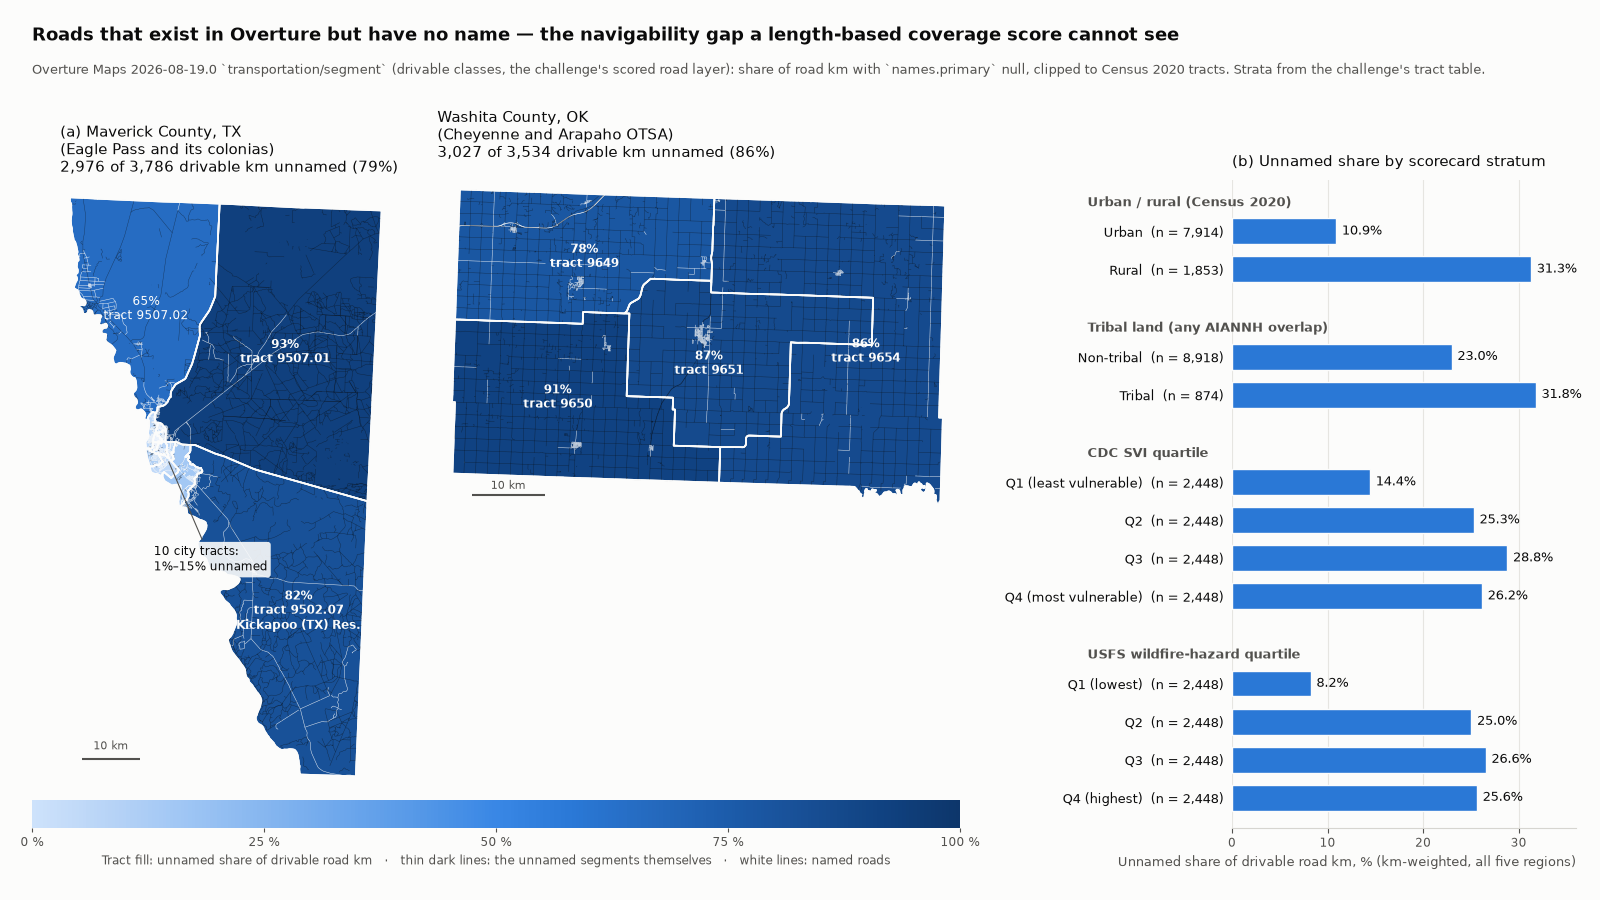

In [8]:
from IPython.display import Image, display
fig = Path("figures/fig_unnamed_roads.png")
display(Image(filename=str(fig), width=1100)) if fig.exists() else print("run figure_unnamed_roads.py to create", fig)

## 5. What this notebook does not reproduce

- The four other regions' features (Texas alone takes ≈ 16 minutes for 4.4 M buildings) — run `features.py` for them; the model cell then picks the cached files up automatically and reproduces the submitted predictions bit-for-bit (the "max |difference|" line prints 0.0).
- The public-leaderboard numbers (WRITEUP §5): they are Zindi's scores of the files listed in §5 and cannot be recomputed without the organiser's reference layers. The implied-correlation arithmetic and the blend weights are in `blend.py` / `blend_v2.py`.
- Ground truth for the unnamed roads: "unnamed" is a property of the Overture transcription (`names.primary` null), not a field survey; see the method card in WRITEUP for what the finding does and does not establish.